## 1. Импорты

In [1]:
import os
import json
import random
import time

import torch
from PIL import Image
from IPython.display import display
from torchvision.models import ResNet34_Weights, ResNet152_Weights, resnet34, resnet152

## 2. Инициализация

In [2]:
device = torch.device("cuda")
folder = "data/imagenet_sample"
torch.hub.set_dir("data/torch")

weights34 = ResNet34_Weights.IMAGENET1K_V1
weights152 = ResNet152_Weights.IMAGENET1K_V2
classes = weights34.meta["categories"]

models = {
    "ResNet34": resnet34(weights=weights34).to(device).eval(),
    "ResNet152": resnet152(weights=weights152).to(device).eval(),
}
transforms = {
    "ResNet34": weights34.transforms(),
    "ResNet152": weights152.transforms(),
}

print(torch.cuda.get_device_name(0))

NVIDIA GeForce RTX 4060 Ti


In [7]:
models["ResNet34"]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## 3. Изображения и правильные классы

In [3]:
image_paths = [
    os.path.join(folder, filename)
    for filename in sorted(os.listdir(folder))
    if filename.lower().endswith((".jpg", ".jpeg"))
]

with open(os.path.join(folder, "manifest.json"), encoding="utf-8") as file:
    samples = json.load(file)

labels = {sample["filename"]: sample["class_id"] for sample in samples}
print(f"Найдено изображений: {len(image_paths)}")

Найдено изображений: 100


## 4. Функция оценки модели

In [4]:
def run_model(model, image_paths, labels, transform, device):
    model.eval()
    correct = 0
    total_loss = 0
    predictions = {}
    total_inference_ms = 0
    start_event = torch.cuda.Event(enable_timing=True)
    end_event = torch.cuda.Event(enable_timing=True)

    with torch.inference_mode():
        torch.cuda.synchronize(device)
        start_time = time.perf_counter()

        for path in image_paths:
            with Image.open(path) as source:
                image = source.convert("RGB")
            tensor = transform(image).unsqueeze(0).to(device)
            target = torch.tensor([labels[os.path.basename(path)]], device=device)

            start_event.record()
            output = model(tensor)
            end_event.record()
            end_event.synchronize()
            inference_ms = start_event.elapsed_time(end_event)
            total_inference_ms += inference_ms
            loss = torch.nn.functional.cross_entropy(output, target)
            probabilities = output.softmax(dim=1)[0]
            scores, indices = probabilities.topk(5)

            correct += (output.argmax(dim=1) == target).sum().item()
            total_loss += loss.item()
            predictions[path] = {
                "indices": indices.tolist(),
                "scores": scores.tolist(),
                "cross_entropy": loss.item(),
                "inference_ms": inference_ms,
            }

    total_time = time.perf_counter() - start_time
    return {
        "accuracy": correct / len(image_paths),
        "cross_entropy": total_loss / len(image_paths),
        "predictions": predictions,
        "total_time": total_time,
        "mean_inference_ms": total_inference_ms / len(image_paths),
    }

## 5. Сравнение моделей
_____

In [5]:
results = {}

for name, model in models.items():
    metrics = run_model(model, image_paths, labels, transforms[name], device)
    results[name] = metrics
    print(name)
    print("Accuracy:", round(metrics["accuracy"] * 100, 1), "%")
    print("Cross-entropy:", round(metrics["cross_entropy"], 4))
    print("Общее время:", round(metrics["total_time"], 2), "с")
    print("Среднее время модели на фото:", round(metrics["mean_inference_ms"], 2), "мс")
    print()

ResNet34
Accuracy: 88.0 %
Cross-entropy: 0.6539
Общее время: 1.61 с
Среднее время модели на фото: 9.68 мс

ResNet152
Accuracy: 95.0 %
Cross-entropy: 0.4824
Общее время: 2.63 с
Среднее время модели на фото: 21.88 мс



## 6. Фотографии и результаты обеих моделей
______

n02437312_Arabian_camel.JPEG — правильный класс: Arabian camel


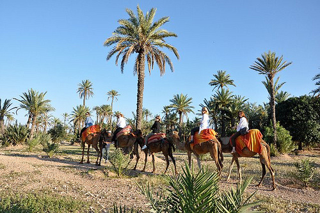

ResNet34: верно, cross-entropy: 0.0392, время модели: 6.17 мс
  Arabian camel: 96.2%
  oxcart: 1.1%
  horse cart: 0.7%
  sorrel: 0.5%
  seashore: 0.4%

ResNet152: верно, cross-entropy: 0.1250, время модели: 15.94 мс
  Arabian camel: 88.3%
  seashore: 0.5%
  hartebeest: 0.4%
  horse cart: 0.3%
  ox: 0.1%

————————————————————————————————————————————————————————————
n07753275_pineapple.JPEG — правильный класс: pineapple


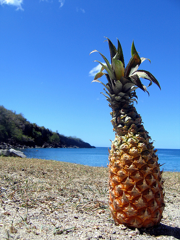

ResNet34: верно, cross-entropy: 0.0014, время модели: 7.57 мс
  pineapple: 99.9%
  ear: 0.1%
  honeycomb: 0.0%
  corn: 0.0%
  banana: 0.0%

ResNet152: верно, cross-entropy: 0.2625, время модели: 16.51 мс
  pineapple: 76.9%
  lakeside: 0.2%
  banana: 0.2%
  seashore: 0.1%
  orange: 0.1%

————————————————————————————————————————————————————————————
n07248320_book_jacket.JPEG — правильный класс: book jacket


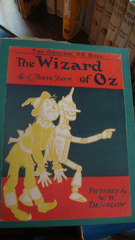

ResNet34: верно, cross-entropy: 0.0065, время модели: 7.34 мс
  book jacket: 99.4%
  comic book: 0.6%
  packet: 0.0%
  jersey: 0.0%
  envelope: 0.0%

ResNet152: верно, cross-entropy: 0.1782, время модели: 20.02 мс
  book jacket: 83.7%
  comic book: 0.6%
  cassette: 0.4%
  bookshop: 0.2%
  menu: 0.1%

————————————————————————————————————————————————————————————
n02099601_golden_retriever.JPEG — правильный класс: golden retriever


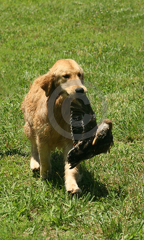

ResNet34: верно, cross-entropy: 0.5618, время модели: 6.20 мс
  golden retriever: 57.0%
  otterhound: 8.5%
  soccer ball: 3.0%
  clumber: 2.9%
  Irish wolfhound: 2.6%

ResNet152: верно, cross-entropy: 0.1398, время модели: 16.52 мс
  golden retriever: 87.0%
  clumber: 0.6%
  kuvasz: 0.3%
  canoe: 0.2%
  cocker spaniel: 0.2%

————————————————————————————————————————————————————————————
n02489166_proboscis_monkey.JPEG — правильный класс: proboscis monkey


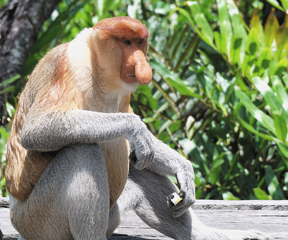

ResNet34: верно, cross-entropy: 0.0004, время модели: 8.05 мс
  proboscis monkey: 100.0%
  macaque: 0.0%
  patas: 0.0%
  guenon: 0.0%
  langur: 0.0%

ResNet152: верно, cross-entropy: 0.1829, время модели: 15.34 мс
  proboscis monkey: 83.3%
  patas: 0.1%
  macaque: 0.0%
  langur: 0.0%
  shoe shop: 0.0%

————————————————————————————————————————————————————————————


In [6]:
for path in random.sample(image_paths, min(5, len(image_paths))):
    filename = os.path.basename(path)
    target = labels[filename]

    print(f"{filename} — правильный класс: {classes[target]}")
    with Image.open(path) as source:
        image = source.convert("RGB")
    image.thumbnail((320, 240))
    display(image)

    for name in models:
        prediction = results[name]["predictions"][path]
        status = "верно" if prediction["indices"][0] == target else "ошибка"
        print(f"{name}: {status}, cross-entropy: {prediction['cross_entropy']:.4f}, "
                f"время модели: {prediction['inference_ms']:.2f} мс")

        for score, index in zip(prediction["scores"], prediction["indices"]):
            print(f"  {classes[index]}: {score:.1%}")
        print()

    print("—" * 60)